# 2D Curved PN Junction Drift-Diffusion Solver

This self-contained notebook derives and implements a 2D steady-state semiconductor solver for a Silicon PN junction with a configurable junction curve $x = f(y)$ under applied bias.

**Numerical architecture:**
- **Spatial discretization:** Finite Volume Method (FVM) on a structured 2D Cartesian grid with half-height control volumes ($\Delta y / 2$) on the insulating Neumann top/bottom walls.
- **Flux discretization:** Scharfetter-Gummel (SG) exponential fitting with a numerically stable Bernoulli function $B(z)$.
- **Nonlinear coupling:** Decoupled Gummel iteration with fixed-quasi-Fermi-level stabilized Poisson updates, semi-implicit SRH recombination (preserving carrier positivity and M-matrix structure), and Boltzmann-reference subtraction at low/reverse bias to eliminate majority-bulk floating-point cancellation.

## 1. Governing Equations, Scaling & Discretization

In $\text{cm}$-based semiconductor units at $T = 300\text{ K}$, steady-state transport is governed by:
1. **Poisson:** $\nabla^2 \psi = -\frac{q}{\varepsilon}\big(p - n + N_{\text{net}}(x,y)\big)$
2. **Continuity:** $\nabla \cdot \mathbf{J}_n = q R$, $\qquad \nabla \cdot \mathbf{J}_p = -q R$
3. **Drift-Diffusion:** $\mathbf{J}_n = -q\mu_n n \nabla\psi + q D_n \nabla n$, $\qquad \mathbf{J}_p = -q\mu_p p \nabla\psi - q D_p \nabla p$, with $D_{n,p} = \mu_{n,p} V_T$.
4. **SRH Recombination:** $R(n,p) = \frac{np - n_i^2}{\tau_p(n + n_i) + \tau_n(p + n_i)}$.

Scaling by $V_T = k_B T / q$, $C_0 = \max(N_A, N_D)$, $L_D = \sqrt{\varepsilon V_T / (q C_0)}$, $\mu_0 = \mu_n$, $t_0 = L_D^2/(\mu_0 V_T)$, and $J_0 = q C_0 \mu_0 V_T / L_D$ gives dimensionless equations:
$$\tilde{\nabla}^2 \tilde{\psi} = \tilde{n} - \tilde{p} - \tilde{N}_{\text{net}}, \qquad -\tilde{\nabla}\cdot\tilde{\mathbf{J}}_n = -\tilde{R}, \qquad +\tilde{\nabla}\cdot\tilde{\mathbf{J}}_p = -\tilde{R}.$$

Across each face $x_{i+1/2,j}$ with $z = \tilde{\psi}_{i+1,j} - \tilde{\psi}_{i,j}$ and $B(z) = z/(e^z - 1)$:
$$\tilde{J}_{n,i+1/2,j} = \frac{\tilde{\mu}_n}{\Delta\tilde{x}}\big[B(z)\tilde{n}_{i+1,j} - B(-z)\tilde{n}_{i,j}\big], \qquad \tilde{J}_{p,i+1/2,j} = -\frac{\tilde{\mu}_p}{\Delta\tilde{x}}\big[B(-z)\tilde{p}_{i+1,j} - B(z)\tilde{p}_{i,j}\big].$$

In [1]:
import time
import warnings
from dataclasses import dataclass, field, replace
from typing import Callable, Optional

import numpy as np
import scipy.sparse as sp
from scipy.linalg import solve_banded
from scipy.sparse.linalg import spsolve
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 120, "axes.grid": False})

# Physical constants (cm-based semiconductor units)
Q = 1.602176634e-19        # elementary charge [C]
KB = 1.380649e-23          # Boltzmann constant [J/K]
EPS0 = 8.854187817e-14     # vacuum permittivity [F/cm]
UM = 1e-4                  # 1 micrometre [cm]


@dataclass(frozen=True)
class DeviceConfig:
    T: float = 300.0             # [K]
    eps_r: float = 11.7          # relative permittivity of Silicon
    ni: float = 1.0e10           # intrinsic concentration [cm^-3]
    mu_n: float = 1400.0         # [cm^2/(V s)]
    mu_p: float = 450.0          # [cm^2/(V s)]
    tau_n: float = 1.0e-6        # [s]
    tau_p: float = 1.0e-6        # [s]
    NA: float = 1.0e16           # p-side (left) acceptor doping [cm^-3]
    ND: float = 1.0e16           # n-side (right) donor doping [cm^-3]
    Lx: float = 4.0 * UM         # domain width [cm]
    Ly: float = 2.0 * UM         # domain height [cm]
    Nx: int = 201
    Ny: int = 81

    @property
    def eps(self) -> float: return self.eps_r * EPS0
    @property
    def VT(self) -> float: return KB * self.T / Q
    @property
    def dx(self) -> float: return self.Lx / (self.Nx - 1)
    @property
    def dy(self) -> float: return self.Ly / (self.Ny - 1)
    def with_(self, **kw) -> "DeviceConfig": return replace(self, **kw)


@dataclass(frozen=True)
class SolverConfig:
    newton_tol: float = 1e-10
    newton_max_iter: int = 50
    newton_clip: float = 2.0
    gummel_max_iter: int = 200
    gummel_inner_newton: int = 2
    gummel_clip: float = 2.0
    tol_psi: float = 1e-6
    tol_phi: float = 1e-6
    tol_phi_floor: float = 1e-4
    tol_poisson_res: float = 1e-8
    enable_srh: bool = True
    dV_forward: float = 0.05
    dV_reverse: float = -0.2
    dV_min: float = 1e-3

    def with_(self, **kw) -> "SolverConfig": return replace(self, **kw)

## 2. Scaling, Bernoulli Function, FVM Operators & Junction Geometry

Notice two key numerical details:
- **Neumann boundary control volumes:** Nodes on $j = 0$ and $j = N_y - 1$ own half-height control volumes ($\Delta y / 2$), so omitting the outer face flux divides the inner $y$-flux by $\Delta y / 2$. Terminal current integration uses matching trapezoid weights $w_j$ ($\Delta y / 2$ at the walls, $\Delta y$ in the interior).
- **Smooth junction curve:** Using $x = f(y)$ with $f'(0) = f'(L_y) = 0$ (such as a cosine interface) avoids symmetry kinks at the Neumann walls, and $w \ge 2.5 \max(\Delta x, \Delta y)\sqrt{1 + \max |f'|^2}$ resolves the normal transition width.

In [2]:
class Scaling:
    """Reference scales: V_T, C0, L_D, mu0, t0 and derived J0, R0, E0."""
    def __init__(self, cfg: DeviceConfig):
        self.VT = cfg.VT
        self.C0 = max(cfg.NA, cfg.ND)
        self.LD = np.sqrt(cfg.eps * self.VT / (Q * self.C0))
        self.mu0 = cfg.mu_n
        self.t0 = self.LD**2 / (self.mu0 * self.VT)
        self.J0 = Q * self.C0 * self.mu0 * self.VT / self.LD
        self.R0 = self.C0 / self.t0
        self.E0 = self.VT / self.LD
        self._f = {
            "psi": self.VT, "V": self.VT, "phi": self.VT,
            "n": self.C0, "p": self.C0, "N": self.C0, "ni": self.C0,
            "x": self.LD, "y": self.LD, "L": self.LD,
            "mu": self.mu0, "tau": self.t0, "t": self.t0,
            "J": self.J0, "R": self.R0, "E": self.E0,
        }

    def scale(self, kind: str, value):
        return np.asarray(value) / self._f[kind] if np.ndim(value) else value / self._f[kind]

    def unscale(self, kind: str, value):
        return np.asarray(value) * self._f[kind] if np.ndim(value) else value * self._f[kind]


def bernoulli(z):
    """B(z) = z / (exp(z) - 1), evaluated stably across all real z."""
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    small = np.abs(z) < 1e-4
    big = z > 500.0
    neg = z < -500.0
    mid = ~(small | big | neg)
    zs = z[small]
    out[small] = 1.0 - zs / 2.0 + zs**2 / 12.0 - zs**4 / 720.0
    out[big] = 0.0
    out[neg] = -z[neg]
    zm = z[mid]
    out[mid] = zm / np.expm1(zm)
    return out if out.ndim else float(out)


class Mesh:
    """Node-centred structured grid. Arrays shaped (Ny, Nx); flat index k = j*Nx + i."""
    def __init__(self, cfg: DeviceConfig, sc: Scaling):
        self.Nx, self.Ny = cfg.Nx, cfg.Ny
        self.N = cfg.Nx * cfg.Ny
        self.x = np.linspace(0.0, cfg.Lx, cfg.Nx)
        self.y = np.linspace(0.0, cfg.Ly, cfg.Ny)
        self.dx_phys, self.dy_phys = cfg.dx, cfg.dy
        self.dx, self.dy = cfg.dx / sc.LD, cfg.dy / sc.LD
        self.X, self.Y = np.meshgrid(self.x, self.y)
        hy = np.full(self.Ny, self.dy)
        hy[0] = hy[-1] = 0.5 * self.dy
        self.hy = hy
        self.wy_phys = hy * sc.LD
        dmask = np.zeros((self.Ny, self.Nx), dtype=bool)
        dmask[:, 0] = dmask[:, -1] = True
        self.dirichlet = dmask.ravel()
        self.interior = ~self.dirichlet
        self.left = np.zeros_like(dmask); self.left[:, 0] = True
        self.right = np.zeros_like(dmask); self.right[:, -1] = True
        self.left, self.right = self.left.ravel(), self.right.ravel()

        k = np.arange(self.N).reshape(self.Ny, self.Nx)
        self.kx_a, self.kx_b = k[:, :-1].ravel(), k[:, 1:].ravel()
        self.ky_a, self.ky_b = k[:-1, :].ravel(), k[1:, :].ravel()
        self.cy_a = 1.0 / (self.dy * np.repeat(hy[:-1], self.Nx))
        self.cy_b = 1.0 / (self.dy * np.repeat(hy[1:], self.Nx))
        self.cx = 1.0 / self.dx**2

    def face_dpsi(self, psi):
        return psi[self.kx_b] - psi[self.kx_a], psi[self.ky_b] - psi[self.ky_a]


def divergence_operator(mesh: Mesh, ax, bx, ay, by) -> sp.csr_matrix:
    """Vectorized FVM divergence assembly for flux F_ab = (a*u_b - b*u_a)/h."""
    cx, cya, cyb = mesh.cx, mesh.cy_a, mesh.cy_b
    ia, ib, ja, jb = mesh.kx_a, mesh.kx_b, mesh.ky_a, mesh.ky_b
    rows = np.concatenate([ia, ia, ib, ib, ja, ja, jb, jb])
    cols = np.concatenate([ib, ia, ib, ia, jb, ja, jb, ja])
    data = np.concatenate([
        cx * ax, -cx * bx, -cx * ax, cx * bx,
        cya * ay, -cya * by, -cyb * ay, cyb * by,
    ])
    return sp.csr_matrix((data, (rows, cols)), shape=(mesh.N, mesh.N))


def apply_dirichlet_rows(A: sp.spmatrix, mask: np.ndarray) -> sp.csc_matrix:
    keep = sp.diags((~mask).astype(float))
    return (keep @ A + sp.diags(mask.astype(float))).tocsc()


def laplacian(mesh: Mesh) -> sp.csr_matrix:
    return divergence_operator(mesh, np.ones(mesh.kx_a.size), np.ones(mesh.kx_a.size),
                               np.ones(mesh.ky_a.size), np.ones(mesh.ky_a.size))


@dataclass
class Curve:
    name: str
    f: Callable
    df: Callable
    d2f: Callable
    def curvature(self, y):
        return np.abs(self.d2f(y)) / (1.0 + self.df(y) ** 2) ** 1.5


def planar(x0: float) -> Curve:
    return Curve("planar", lambda y: np.full_like(np.asarray(y, float), x0),
                 lambda y: np.zeros_like(np.asarray(y, float)),
                 lambda y: np.zeros_like(np.asarray(y, float)))


def cosine(x0: float, A: float, Ly: float, m: int = 1) -> Curve:
    k = 2.0 * np.pi * m / Ly
    return Curve(f"cosine(A={A * 1e4:g}um)",
                 lambda y: x0 + A * np.cos(k * np.asarray(y)),
                 lambda y: -A * k * np.sin(k * np.asarray(y)),
                 lambda y: -A * k**2 * np.cos(k * np.asarray(y)))


def parabolic(x0: float, c: float, Ly: float) -> Curve:
    yc = Ly / 2.0
    return Curve("parabolic",
                 lambda y: x0 + c * (np.asarray(y) - yc) ** 2,
                 lambda y: 2.0 * c * (np.asarray(y) - yc),
                 lambda y: np.full_like(np.asarray(y, float), 2.0 * c))


def circular_arc(xc: float, yc: float, R: float) -> Curve:
    def s(y):
        d = R**2 - (np.asarray(y) - yc) ** 2
        if np.any(d <= 0):
            raise ValueError("circular arc: |y - yc| must be < R everywhere")
        return np.sqrt(d)
    return Curve("circular_arc", lambda y: xc - s(y),
                 lambda y: (np.asarray(y) - yc) / s(y), lambda y: R**2 / s(y) ** 3)


def min_transition_width(cfg: DeviceConfig, curve: Curve, n_sample: int = 2001) -> float:
    y = np.linspace(0.0, cfg.Ly, n_sample)
    slope = np.max(np.abs(curve.df(y)))
    return 2.5 * max(cfg.dx, cfg.dy) * np.sqrt(1.0 + slope**2)


def check_walls(cfg: DeviceConfig, curve: Curve, tol: float = 0.05) -> None:
    for yw in (0.0, cfg.Ly):
        s = float(np.abs(curve.df(np.array([yw]))[0]))
        if s > tol:
            warnings.warn(f"{curve.name}: |f'| = {s:.3f} at y = {yw * 1e4:g} um")


def net_doping(cfg: DeviceConfig, X, Y, curve: Curve, w: float):
    return 0.5 * (cfg.ND - cfg.NA) + 0.5 * (cfg.ND + cfg.NA) * np.tanh((X - curve.f(Y)) / w)

## 3. Equilibrium Newton-Raphson, Scharfetter-Gummel Continuity & Gummel Solver

- **Equilibrium ($V_{\text{app}}=0$):** Solves $L\tilde{\psi} - \tilde{n}_i e^{\tilde{\psi}} + \tilde{n}_i e^{-\tilde{\psi}} + \tilde{N}_{\text{net}} = 0$ with Jacobian $L - \text{diag}(\tilde{n}+\tilde{p})$.
- **Continuity & semi-implicit SRH:** $A_n = -\nabla_h\cdot\tilde{\mathbf{J}}_n$ and $A_p = +\nabla_h\cdot\tilde{\mathbf{J}}_p$ have positive diagonals and non-positive off-diagonals. Writing $R=(np-n_i^2)/D$ moves $p/D$ (or $n/D$) onto the diagonal so both solves remain M-matrices with non-negative RHS.
- **Boltzmann-reference subtraction ($V \le 0.30\text{ V}$):** Because $A_n(\tilde{\psi})[\tilde{n}_i e^{\tilde{\psi}}] \equiv 0$ and $A_p(\tilde{\psi})[\tilde{n}_i e^{-\tilde{\psi}+V/V_T}] \equiv 0$ identically, solving for $\delta\tilde{n} = \tilde{n} - \tilde{n}_i e^{\tilde{\psi}}$ and $\delta\tilde{p} = \tilde{p} - \tilde{n}_i e^{-\tilde{\psi}+V/V_T}$ eliminates $O(1)$ cancellation in the neutral majority-carrier regions, giving machine-precision current conservation even at nanoamp/picoamp reverse currents.

In [3]:
class ConvergenceError(RuntimeError):
    pass


class Device:
    def __init__(self, cfg: DeviceConfig = DeviceConfig(), curve: Optional[Curve] = None,
                 w: Optional[float] = None, check: bool = True):
        self.cfg = cfg
        self.sc = sc = Scaling(cfg)
        self.mesh = mesh = Mesh(cfg, sc)
        self.curve = curve if curve is not None else planar(cfg.Lx / 2)
        w_min = min_transition_width(cfg, self.curve)
        self.w = w if w is not None else w_min
        if check:
            if self.w < w_min * (1 - 1e-9):
                raise ValueError(f"w = {self.w * 1e4:.4f} um < required {w_min * 1e4:.4f} um")
            check_walls(cfg, self.curve)
        self.Nnet_phys = net_doping(cfg, mesh.X, mesh.Y, self.curve, self.w)
        self.N = sc.scale("N", self.Nnet_phys).ravel()
        self.ni = sc.scale("ni", cfg.ni)
        self.mu_n = cfg.mu_n / sc.mu0
        self.mu_p = cfg.mu_p / sc.mu0
        self.tau_n = sc.scale("tau", cfg.tau_n)
        self.tau_p = sc.scale("tau", cfg.tau_p)
        pL = cfg.NA / 2 + np.sqrt((cfg.NA / 2) ** 2 + cfg.ni**2)
        nR = cfg.ND / 2 + np.sqrt((cfg.ND / 2) ** 2 + cfg.ni**2)
        self.pL, self.nL = sc.scale("p", pL), sc.scale("n", cfg.ni**2 / pL)
        self.nR, self.pR = sc.scale("n", nR), sc.scale("p", cfg.ni**2 / nR)
        self.psiL0 = -np.log(pL / cfg.ni)
        self.psiR = np.log(nR / cfg.ni)
        self.L = laplacian(mesh)
        self.L_bc = apply_dirichlet_rows(self.L, mesh.dirichlet)

    def psi_bc(self, V: float) -> np.ndarray:
        b = np.zeros(self.mesh.N)
        b[self.mesh.left] = self.psiL0 + V / self.sc.VT
        b[self.mesh.right] = self.psiR
        return b

    def n_bc(self) -> np.ndarray:
        b = np.zeros(self.mesh.N)
        b[self.mesh.left], b[self.mesh.right] = self.nL, self.nR
        return b

    def p_bc(self) -> np.ndarray:
        b = np.zeros(self.mesh.N)
        b[self.mesh.left], b[self.mesh.right] = self.pL, self.pR
        return b

    def reshape(self, u):
        return np.asarray(u).reshape(self.mesh.Ny, self.mesh.Nx)


@dataclass
class State:
    psi: np.ndarray
    n: np.ndarray
    p: np.ndarray
    V: float = 0.0
    iterations: int = 0
    history: list = field(default_factory=list)
    roundoff_limited: bool = False
    dn: Optional[np.ndarray] = None
    dp: Optional[np.ndarray] = None

    def copy(self) -> "State":
        return State(self.psi.copy(), self.n.copy(), self.p.copy(), self.V, self.iterations,
                     list(self.history), self.roundoff_limited,
                     None if self.dn is None else self.dn.copy(),
                     None if self.dp is None else self.dp.copy())


def poisson_residual(dev: Device, psi, n, p, V: float) -> np.ndarray:
    F = dev.L @ psi - n + p + dev.N
    d = dev.mesh.dirichlet
    F[d] = psi[d] - dev.psi_bc(V)[d]
    return F


def poisson_jacobian(dev: Device, n, p) -> sp.csc_matrix:
    return (dev.L_bc - sp.diags((n + p) * dev.mesh.interior)).tocsc()


def solve_equilibrium(dev: Device, scfg: SolverConfig = SolverConfig(), verbose=False) -> State:
    psi = np.arcsinh(dev.N / (2 * dev.ni))
    d = dev.mesh.dirichlet
    psi[d] = dev.psi_bc(0.0)[d]
    hist = []
    for it in range(1, scfg.newton_max_iter + 1):
        n, p = dev.ni * np.exp(psi), dev.ni * np.exp(-psi)
        F = poisson_residual(dev, psi, n, p, 0.0)
        dpsi = np.clip(spsolve(poisson_jacobian(dev, n, p), -F), -scfg.newton_clip, scfg.newton_clip)
        psi += dpsi
        step, res = np.max(np.abs(dpsi)), np.max(np.abs(F))
        hist.append((step, res))
        if verbose:
            print(f"  Newton {it:2d}: max|dpsi| = {step:.3e}  max|F| = {res:.3e}")
        if step < scfg.newton_tol:
            n, p = dev.ni * np.exp(psi), dev.ni * np.exp(-psi)
            return State(psi, n, p, 0.0, it, hist)
    raise ConvergenceError("equilibrium Newton did not converge")


def assemble_electron_matrix(dev: Device, psi) -> sp.csr_matrix:
    zx, zy = dev.mesh.face_dpsi(psi)
    mu = dev.mu_n
    return -divergence_operator(dev.mesh, mu * bernoulli(zx), mu * bernoulli(-zx),
                                mu * bernoulli(zy), mu * bernoulli(-zy))


def assemble_hole_matrix(dev: Device, psi) -> sp.csr_matrix:
    zx, zy = dev.mesh.face_dpsi(psi)
    mu = dev.mu_p
    return divergence_operator(dev.mesh, -mu * bernoulli(-zx), -mu * bernoulli(zx),
                               -mu * bernoulli(-zy), -mu * bernoulli(zy))


def srh_denominator(dev: Device, n, p):
    return dev.tau_p * (n + dev.ni) + dev.tau_n * (p + dev.ni)


def compute_srh(dev: Device, n, p):
    return (n * p - dev.ni**2) / srh_denominator(dev, n, p)


def _solve_continuity(A, bc, d, other, Dn, ni, ref=None, enable_srh=True):
    if enable_srh:
        A = A + sp.diags(other / Dn)
        rhs = (ni**2 - (ref * other if ref is not None else 0.0)) / Dn
    else:
        rhs = np.zeros_like(bc)
    rhs[d] = bc[d] - (ref[d] if ref is not None else 0.0)
    sol = spsolve(apply_dirichlet_rows(A, d), rhs)
    return (ref + sol, sol) if ref is not None else (sol, None)


def solve_electrons(dev: Device, psi, n_old, p_old, enable_srh=True):
    Dn = srh_denominator(dev, n_old, p_old) if enable_srh else None
    n, _ = _solve_continuity(assemble_electron_matrix(dev, psi), dev.n_bc(),
                             dev.mesh.dirichlet, p_old, Dn, dev.ni, None, enable_srh)
    return n


def solve_holes(dev: Device, psi, n_old, p_old, enable_srh=True):
    Dn = srh_denominator(dev, n_old, p_old) if enable_srh else None
    p, _ = _solve_continuity(assemble_hole_matrix(dev, psi), dev.p_bc(),
                             dev.mesh.dirichlet, n_old, Dn, dev.ni, None, enable_srh)
    return p


def quasi_fermi(dev: Device, psi, n, p):
    return psi - np.log(n / dev.ni), psi + np.log(p / dev.ni)


def solve_bias(dev: Device, V: float, init: State, scfg: SolverConfig = SolverConfig(),
               verbose=False) -> State:
    psi, n, p = init.psi.copy(), init.n.copy(), init.p.copy()
    d, interior = dev.mesh.dirichlet, dev.mesh.interior
    n[d], p[d] = dev.n_bc()[d], dev.p_bc()[d]
    hist = []
    omega, prev_res = 1.0, np.inf
    use_delta = V <= 0.30
    for it in range(1, scfg.gummel_max_iter + 1):
        psi0 = psi.copy()
        phin0, phip0 = quasi_fermi(dev, psi, n, p)
        for _ in range(scfg.gummel_inner_newton):
            F = poisson_residual(dev, psi, n, p, V)
            dpsi = spsolve(poisson_jacobian(dev, n, p), -F)
            dpsi[interior] = np.clip(dpsi[interior], -scfg.gummel_clip, scfg.gummel_clip) * omega
            psi += dpsi
            n[interior] *= np.exp(dpsi[interior])
            p[interior] *= np.exp(-dpsi[interior])
            if np.max(np.abs(dpsi)) < 0.1 * scfg.tol_psi:
                break
        n_ref = dev.ni * np.exp(psi) if use_delta else None
        p_ref = dev.ni * np.exp(-psi + V / dev.sc.VT) if use_delta else None
        Dn = srh_denominator(dev, n, p) if scfg.enable_srh else None
        n_new, dn_arr = _solve_continuity(assemble_electron_matrix(dev, psi), dev.n_bc(),
                                          d, p, Dn, dev.ni, n_ref, scfg.enable_srh)
        Dn = srh_denominator(dev, n_new, p) if scfg.enable_srh else None
        p_new, dp_arr = _solve_continuity(assemble_hole_matrix(dev, psi), dev.p_bc(),
                                          d, n_new, Dn, dev.ni, p_ref, scfg.enable_srh)
        if not (np.all(np.isfinite(n_new)) and np.all(np.isfinite(p_new))
                and np.all(n_new > 0) and np.all(p_new > 0)):
            raise ConvergenceError(f"non-physical carriers at V = {V:.3f} V (iter {it})")
        n, p = n_new, p_new
        phin, phip = quasi_fermi(dev, psi, n, p)
        e_psi = np.max(np.abs(psi - psi0))
        e_n, e_p = np.max(np.abs(phin - phin0)), np.max(np.abs(phip - phip0))
        res = np.max(np.abs(poisson_residual(dev, psi, n, p, V)))
        hist.append((e_psi, e_n, e_p, res))
        if res > 1.5 * prev_res and it > 3:
            omega = 0.5
        prev_res = res
        psi_ok = e_psi < scfg.tol_psi and res < scfg.tol_poisson_res
        e_phi = max(e_n, e_p)
        if psi_ok and e_phi < scfg.tol_phi:
            return State(psi, n, p, V, it, hist, dn=dn_arr, dp=dp_arr)
        if psi_ok and e_phi < scfg.tol_phi_floor and it >= 6:
            recent = [max(h[1], h[2]) for h in hist[-6:]]
            if min(recent[3:]) > 0.5 * min(recent[:3]):
                return State(psi, n, p, V, it, hist, roundoff_limited=True, dn=dn_arr, dp=dp_arr)
    raise ConvergenceError(f"Gummel did not converge at V = {V:.3f} V")


def ramp(dev: Device, start: State, V_target: float, dV: float,
         scfg: SolverConfig = SolverConfig()) -> State:
    state, V = start, start.V
    step, sgn = abs(dV), np.sign(V_target - start.V)
    while abs(V_target - V) > 1e-12:
        h = min(step, abs(V_target - V))
        try:
            state = solve_bias(dev, V + sgn * h, state, scfg)
            V = state.V
            step = min(abs(dV), 2 * step)
        except ConvergenceError:
            step /= 2
            if step < scfg.dV_min:
                raise
    return state


def run_voltage_sweep(dev: Device, voltages, eq: Optional[State] = None,
                      scfg: SolverConfig = SolverConfig()):
    eq = eq if eq is not None else solve_equilibrium(dev, scfg)
    voltages = np.unique(np.round(np.asarray(voltages, float), 10))
    s0 = solve_bias(dev, 0.0, eq, scfg)
    out = {0.0: s0}
    for branch, dV in ((voltages[voltages > 0], scfg.dV_forward),
                       (voltages[voltages < 0][::-1], scfg.dV_reverse)):
        state = s0
        for V in branch:
            state = ramp(dev, state, float(V), dV, scfg)
            out[float(V)] = state
    return dict(sorted(out.items()))


def solve_equilibrium_1d(cfg: DeviceConfig, Nx: int, w: float, x0: Optional[float] = None,
                         tol: float = 1e-12, max_iter: int = 100):
    sc = Scaling(cfg)
    x0 = cfg.Lx / 2 if x0 is None else x0
    x = np.linspace(0, cfg.Lx, Nx)
    h = (x[1] - x[0]) / sc.LD
    Nn = (0.5 * (cfg.ND - cfg.NA) + 0.5 * (cfg.ND + cfg.NA) * np.tanh((x - x0) / w)) / sc.C0
    ni = cfg.ni / sc.C0
    pL = cfg.NA / 2 + np.sqrt((cfg.NA / 2) ** 2 + cfg.ni**2)
    nR = cfg.ND / 2 + np.sqrt((cfg.ND / 2) ** 2 + cfg.ni**2)
    psi = np.arcsinh(Nn / (2 * ni))
    psi[0], psi[-1] = -np.log(pL / cfg.ni), np.log(nR / cfg.ni)
    for _ in range(max_iter):
        F = np.zeros(Nx)
        F[1:-1] = (psi[2:] - 2 * psi[1:-1] + psi[:-2]) / h**2 - ni * np.exp(psi[1:-1]) \
            + ni * np.exp(-psi[1:-1]) + Nn[1:-1]
        ab = np.zeros((3, Nx))
        ab[1, :] = 1.0
        ab[1, 1:-1] = -2 / h**2 - ni * (np.exp(psi[1:-1]) + np.exp(-psi[1:-1]))
        ab[0, 2:] = ab[2, :-2] = 1 / h**2
        dpsi = np.clip(solve_banded((1, 1), ab, -F), -2, 2)
        psi += dpsi
        if np.max(np.abs(dpsi)) < tol:
            return x, psi * sc.VT
    raise ConvergenceError("1D Newton did not converge")

## 4. Post-Processing & Visualization Helpers

Electric field components $E_x, E_y$ are computed from face-centred FVM differences and averaged to cell centres before computing $|\mathbf{E}| = \sqrt{E_x^2 + E_y^2}$. Current density is evaluated from exact Scharfetter-Gummel face fluxes and integrated over $y$ with trapezoid weights matching the FVM half-cells on the Neumann walls.

In [4]:
def physical(dev: Device, st: State):
    sc = dev.sc
    return (dev.reshape(sc.unscale("psi", st.psi)), dev.reshape(sc.unscale("n", st.n)),
            dev.reshape(sc.unscale("p", st.p)))


def electric_field(dev: Device, st: State):
    m = dev.mesh
    psi = dev.reshape(st.psi) * dev.sc.VT
    Ex_f = -(psi[:, 1:] - psi[:, :-1]) / m.dx_phys
    Ey_f = -(psi[1:, :] - psi[:-1, :]) / m.dy_phys
    Ex = 0.5 * (Ex_f[1:, :] + Ex_f[:-1, :])
    Ey = 0.5 * (Ey_f[:, 1:] + Ey_f[:, :-1])
    xc, yc = 0.5 * (m.x[1:] + m.x[:-1]), 0.5 * (m.y[1:] + m.y[:-1])
    return xc, yc, Ex, Ey, np.hypot(Ex, Ey)


def face_currents_x(dev: Device, st: State):
    psi = dev.reshape(st.psi)
    n = dev.reshape(st.dn if st.dn is not None else st.n)
    p = dev.reshape(st.dp if st.dp is not None else st.p)
    z = psi[:, 1:] - psi[:, :-1]
    h = dev.mesh.dx
    Jn = dev.mu_n / h * (bernoulli(z) * n[:, 1:] - bernoulli(-z) * n[:, :-1])
    Jp = -dev.mu_p / h * (bernoulli(-z) * p[:, 1:] - bernoulli(z) * p[:, :-1])
    return dev.sc.unscale("J", Jn), dev.sc.unscale("J", Jp)


def column_currents(dev: Device, st: State):
    Jn, Jp = face_currents_x(dev, st)
    return dev.mesh.wy_phys @ (Jn + Jp)


def terminal_current(dev: Device, st: State) -> float:
    return float(np.mean(column_currents(dev, st)))


def current_conservation_error(dev: Device, st: State) -> float:
    I = column_currents(dev, st)
    return float(np.max(np.abs(I - I.mean())) / max(abs(I.mean()), 1e-300))


def space_charge(dev: Device, st: State):
    _, n, p = physical(dev, st)
    return p - n + dev.Nnet_phys


def depletion_width(dev: Device, st: State, row: int = None):
    row = dev.mesh.Ny // 2 if row is None else row
    _, n, p = physical(dev, st)
    x, n, p = dev.mesh.x, n[row], p[row]
    i_n = np.argmax(n >= dev.cfg.ND / 2)
    xn = np.interp(dev.cfg.ND / 2, n[i_n - 1:i_n + 1], x[i_n - 1:i_n + 1])
    i_p = np.where(p >= dev.cfg.NA / 2)[0][-1]
    xp = np.interp(dev.cfg.NA / 2, p[i_p:i_p + 2][::-1], x[i_p:i_p + 2][::-1])
    return xn - xp


def built_in_potential(cfg) -> float:
    return cfg.VT * np.log(cfg.NA * cfg.ND / cfg.ni**2)


def abrupt_depletion_width(cfg, V: float = 0.0, tail_correction: bool = True) -> float:
    Veff = built_in_potential(cfg) - V - (2 * cfg.VT if tail_correction else 0.0)
    return np.sqrt(2 * cfg.eps * Veff / Q * (cfg.NA + cfg.ND) / (cfg.NA * cfg.ND))


def abrupt_peak_field(cfg, V: float = 0.0, tail_correction: bool = True) -> float:
    Veff = built_in_potential(cfg) - V - (2 * cfg.VT if tail_correction else 0.0)
    return 2 * Veff / abrupt_depletion_width(cfg, V, tail_correction)


def ideality_factor(V, I, VT, vmin=0.25, vmax=0.55):
    V, I = np.asarray(V), np.abs(np.asarray(I))
    sel = (V >= vmin) & (V <= vmax)
    slope = np.polyfit(V[sel], np.log(I[sel]), 1)[0]
    return 1.0 / (slope * VT)


def plot_dashboard(dev: Device, st: State, title: str = None):
    m, um = dev.mesh, 1e4
    psi, n, p = physical(dev, st)
    xc, yc, Ex, Ey, Emag = electric_field(dev, st)
    yy = np.linspace(0, dev.cfg.Ly, 400)
    fy = dev.curve.f(yy)
    fig, ax = plt.subplots(2, 2, figsize=(11.5, 7.0), constrained_layout=True)
    panels = [
        (ax[0, 0], m.x, m.y, psi, r"$\psi$ [V]", "viridis"),
        (ax[1, 0], m.x, m.y, np.log10(n), r"$\log_{10} n$ [cm$^{-3}$]", "Blues"),
        (ax[1, 1], m.x, m.y, np.log10(p), r"$\log_{10} p$ [cm$^{-3}$]", "Reds"),
    ]
    for a, x, y, Z, lab, cmap in panels:
        pc = a.pcolormesh(x * um, y * um, Z, shading="auto", cmap=cmap)
        fig.colorbar(pc, ax=a, label=lab)
        a.plot(fy * um, yy * um, "w--", lw=1.2)
        a.set_xlabel(r"$x$ [$\mu$m]"); a.set_ylabel(r"$y$ [$\mu$m]")
        a.set_aspect("equal")

    ax_E = ax[0, 1]
    nx_q = 34
    ny_q = max(4, round(nx_q * dev.cfg.Ly / dev.cfg.Lx))
    sx = max(1, round(len(xc) / nx_q))
    sy = max(1, round(len(yc) / ny_q))
    ix = slice(sx // 2, None, sx)
    iy = slice(sy // 2, None, sy)
    Xq, Yq = np.meshgrid(xc[ix] * um, yc[iy] * um)
    Ex_q, Ey_q, Em_q = Ex[iy, ix], Ey[iy, ix], Emag[iy, ix]
    Emax = max(float(Emag.max()), 1e-30)
    valid = Em_q > 1e-3 * Emax
    Ux = Ex_q[valid] / Em_q[valid]
    Uy = Ey_q[valid] / Em_q[valid]
    dx_q = (xc[1] - xc[0]) * sx * um
    dy_q = (yc[1] - yc[0]) * sy * um
    arrow_len = 0.75 * min(dx_q, dy_q)

    ax_E.set_facecolor("#11131a")
    ax_E.plot(fy * um, yy * um, "w--", lw=1.1, alpha=0.65, zorder=2)
    q = ax_E.quiver(
        Xq[valid], Yq[valid], Ux, Uy, Em_q[valid],
        cmap="plasma", angles="xy", scale_units="xy", scale=1.0 / arrow_len,
        pivot="mid", width=0.0042, headwidth=3.8, headlength=4.2, headaxislength=3.6,
        zorder=3,
    )
    q.set_clim(0.0, Emax)
    fig.colorbar(q, ax=ax_E, label=r"$|\mathbf{E}|$ [V/cm]")
    ax_E.set_xlabel(r"$x$ [$\mu$m]"); ax_E.set_ylabel(r"$y$ [$\mu$m]")
    ax_E.set_aspect("equal")
    ax_E.set_xlim(0, dev.cfg.Lx * um); ax_E.set_ylim(0, dev.cfg.Ly * um)

    fig.suptitle(title or f"{dev.curve.name}, $V_{{app}}$ = {st.V:+.2f} V")
    return fig


def plot_iv(V, I, VT=None):
    V, I = np.asarray(V), np.asarray(I)
    fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
    ax.semilogy(V, np.abs(I), "o-", ms=4)
    ax.set_xlabel(r"$V_{app}$ [V]"); ax.set_ylabel(r"$|I|$ [A/cm]")
    ax.grid(True, which="both", alpha=0.3)
    if VT is not None and np.sum(V > 0.3) >= 3:
        ax.set_title(f"I-V Characteristic (ideality n = {ideality_factor(V, I, VT):.3f}, 0.25-0.55 V)")
    return fig

## 5. Numerical & Physical Verification Benchmarks

Before running parameter sweeps, we verify:
1. Bernoulli stability (`B(0) = 1`, `B(z) - B(-z) = -z` across `[-1000, 1000]`) and scaling round-trip.
2. Equilibrium Newton convergence (< 15 iterations), 1D planar symmetry, fine-grid 1D agreement, $w$-convergence toward the Debye-tail-corrected abrupt formula, and global charge neutrality.
3. SG M-matrix sign pattern and exact Boltzmann recovery at $V = 0$ with $R = 0$.

In [5]:
# 1. Bernoulli & Scaling
z_test = np.concatenate([np.linspace(-1000, 1000, 20001), [0.0, 1e-4, -1e-4, 500.0, -500.0]])
b_err = np.max(np.abs((bernoulli(z_test) - bernoulli(-z_test)) + z_test) / np.maximum(1.0, np.abs(z_test)))
sc0 = Scaling(DeviceConfig())
print(f"Bernoulli B(0) = {bernoulli(0.0):.1f}, max rel identity error = {b_err:.2e}")
print(f"Debye length L_D = {sc0.LD * 1e4:.4f} um, V_T = {sc0.VT * 1e3:.3f} mV")
assert bernoulli(0.0) == 1.0 and b_err < 1e-12

# 2. Planar 2D Equilibrium & 1D Benchmark
cfg = DeviceConfig()
dev_planar = Device(cfg)
eq_planar = solve_equilibrium(dev_planar, verbose=True)
psi_2d = dev_planar.reshape(eq_planar.psi) * sc0.VT
vbi_num = psi_2d[0, -1] - psi_2d[0, 0]
x1, psi1 = solve_equilibrium_1d(cfg, 4 * (cfg.Nx - 1) + 1, dev_planar.w)
err_1d = np.max(np.abs(psi_2d[cfg.Ny // 2] - np.interp(dev_planar.mesh.x, x1, psi1)))
Emax_eq = electric_field(dev_planar, eq_planar)[4].max()
W_eq = depletion_width(dev_planar, eq_planar)
rho_eq = space_charge(dev_planar, eq_planar)

print(f"\nBuilt-in potential: num = {vbi_num:.6f} V, analytic = {built_in_potential(cfg):.6f} V")
print(f"Row-to-row max diff (scaled) = {np.max(np.abs(dev_planar.reshape(eq_planar.psi) - dev_planar.reshape(eq_planar.psi)[0])):.2e}")
print(f"2D vs 4x-fine 1D max potential diff = {err_1d:.2e} V")
print(f"w = {dev_planar.w*1e4:.4f} um (w/dx = {dev_planar.w/cfg.dx:.2f}, w/Wd = {dev_planar.w/abrupt_depletion_width(cfg):.3f})")
print(f"|E|max = {Emax_eq:.3e} V/cm (vs abrupt {abrupt_peak_field(cfg):.3e}: {Emax_eq/abrupt_peak_field(cfg)-1:+.2%})")
print(f"W_d    = {W_eq*1e4:.4f} um   (vs abrupt {abrupt_depletion_width(cfg)*1e4:.4f} um: {W_eq/abrupt_depletion_width(cfg)-1:+.2%})")
print(f"Net integrated charge ratio = {abs(np.sum(rho_eq))/np.sum(np.abs(rho_eq)):.2e}")

# 2b. w-convergence study in 1D
cfg_1d = DeviceConfig(Nx=8001)
Eab = abrupt_peak_field(cfg_1d)
print("\n1D w-convergence vs abrupt peak field:")
for w_um in (0.08, 0.04, 0.02, 0.01):
    xw, psiw = solve_equilibrium_1d(cfg_1d, cfg_1d.Nx, w_um * UM)
    Ew = np.max(np.abs(np.diff(psiw) / np.diff(xw)))
    print(f"  w = {w_um:.2f} um -> E_max = {Ew:.4e} V/cm (rel diff = {Ew/Eab - 1:+.4f})")

# 3. Continuity M-matrix & Boltzmann Recovery at V=0 (R=0)
An = assemble_electron_matrix(dev_planar, eq_planar.psi).tocsr()
Ap = assemble_hole_matrix(dev_planar, eq_planar.psi).tocsr()
for name, A in (("A_n", An), ("A_p", Ap)):
    diag = A.diagonal()
    off = (A - sp.diags(diag)).tocsr()[dev_planar.mesh.interior]
    assert np.all(diag[dev_planar.mesh.interior] > 0) and (off.data.size == 0 or off.data.max() <= 0)
n_v0 = solve_electrons(dev_planar, eq_planar.psi, eq_planar.n, eq_planar.p, enable_srh=False)
p_v0 = solve_holes(dev_planar, eq_planar.psi, eq_planar.n, eq_planar.p, enable_srh=False)
print(f"\nBoltzmann recovery (V=0, R=0): max rel err n = {np.max(np.abs(n_v0/eq_planar.n - 1)):.2e}, "
      f"p = {np.max(np.abs(p_v0/eq_planar.p - 1)):.2e}")

Bernoulli B(0) = 1.0, max rel identity error = 3.22e-16
Debye length L_D = 0.0409 um, V_T = 25.852 mV
  Newton  1: max|dpsi| = 2.000e+00  max|F| = 5.032e+01
  Newton  2: max|dpsi| = 2.000e+00  max|F| = 4.169e+01
  Newton  3: max|dpsi| = 2.000e+00  max|F| = 3.330e+01
  Newton  4: max|dpsi| = 2.000e+00  max|F| = 2.494e+01
  Newton  5: max|dpsi| = 2.000e+00  max|F| = 1.658e+01
  Newton  6: max|dpsi| = 6.010e-01  max|F| = 5.023e+00
  Newton  7: max|dpsi| = 4.517e-07  max|F| = 2.082e-06
  Newton  8: max|dpsi| = 3.432e-14  max|F| = 6.783e-14

Built-in potential: num = 0.714317 V, analytic = 0.714317 V
Row-to-row max diff (scaled) = 2.13e-14
2D vs 4x-fine 1D max potential diff = 3.32e-04 V
w = 0.0625 um (w/dx = 3.13, w/Wd = 0.151)
|E|max = 2.639e+04 V/cm (vs abrupt 3.201e+04: -17.56%)
W_d    = 0.4161 um   (vs abrupt 0.4140 um: +0.52%)
Net integrated charge ratio = 5.42e-15

1D w-convergence vs abrupt peak field:
  w = 0.08 um -> E_max = 2.5325e+04 V/cm (rel diff = -0.2089)
  w = 0.04 um -> E_

## 6. Planar Bias Sweep ($-3.0\text{ V} \to +0.65\text{ V}$) & Field/Carrier Dashboards

We check that $L_x \ge 3 W_d(-3.0\text{ V})$, run the full forward and reverse Gummel voltage sweep, verify FVM current conservation across all $N_x - 1$ columns, inspect the fitted forward ideality factor, and render 2×2 dashboards at equilibrium ($0\text{ V}$), forward bias ($+0.60\text{ V}$), and reverse bias ($-3.0\text{ V}$).

Domain check at -3.00 V: W_d = 0.973 um, Lx/W_d = 4.11
Planar sweep (29 bias points) solved in 46.6 s

  V [V]      I [A/cm]    cons.err  iters
  -3.00   -9.3655e-12    2.92e-13      6
  -2.80   -8.9342e-12    3.28e-13      6
  -2.60   -8.4930e-12    3.10e-13      6
  -2.40   -8.0383e-12    1.84e-13      6
  -2.20   -7.5664e-12    2.49e-13      6
  -2.00   -7.0788e-12    2.58e-13      6
  -1.80   -6.5744e-12    2.84e-13      6
  -1.60   -6.0491e-12    2.82e-13      6
  -1.40   -5.4994e-12    2.97e-13      6
  -1.20   -4.9221e-12    2.93e-13      6
  -1.00   -4.3130e-12    3.36e-13      6
  -0.80   -3.6655e-12    3.50e-13      6
  -0.60   -2.9695e-12    3.45e-13      6
  -0.40   -2.2077e-12    3.08e-13      6
  -0.20   -1.3455e-12    3.13e-13      6
   0.00    2.5911e-28    0.00e+00      1
   0.05    1.4683e-12    3.44e-13      5
   0.10    7.4431e-12    2.78e-13      5
   0.15    3.8287e-11    4.14e-13      5
   0.20    2.2264e-10    4.98e-13      5
   0.25    1.4138e-09    5.41e-13   

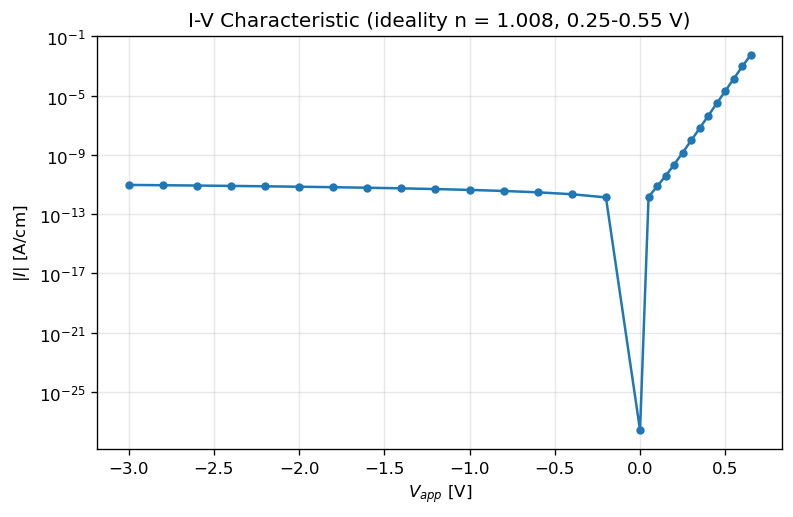

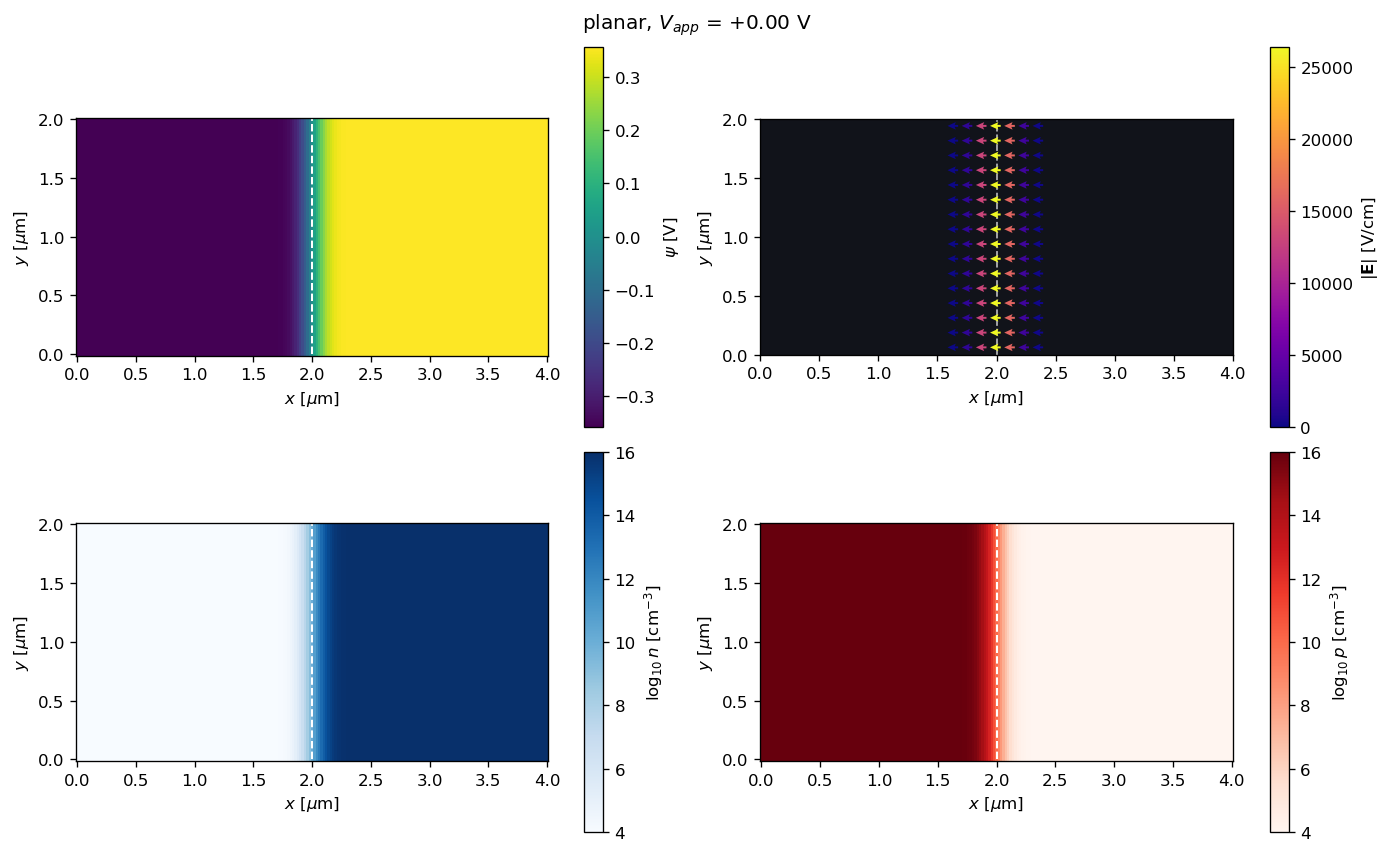

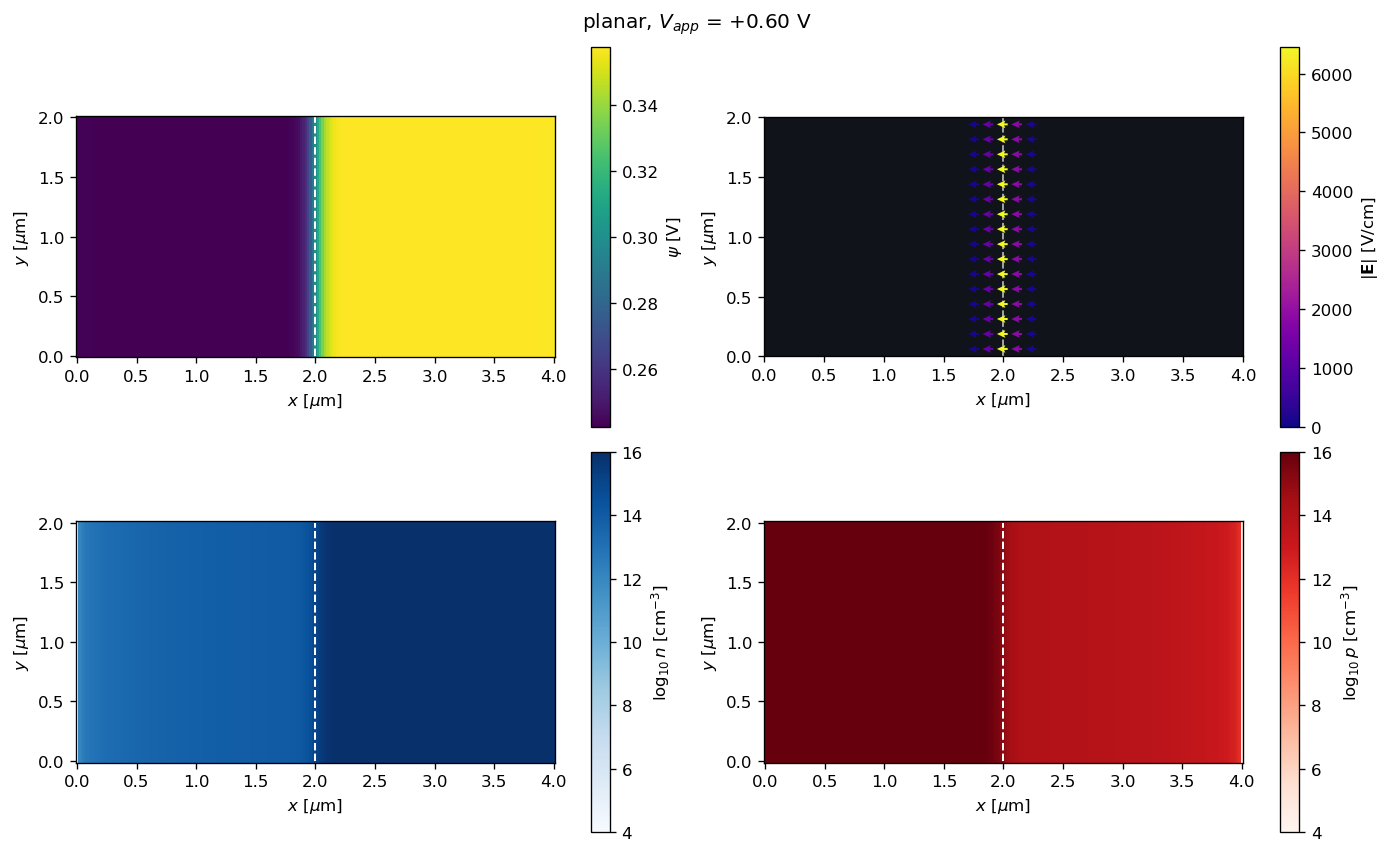

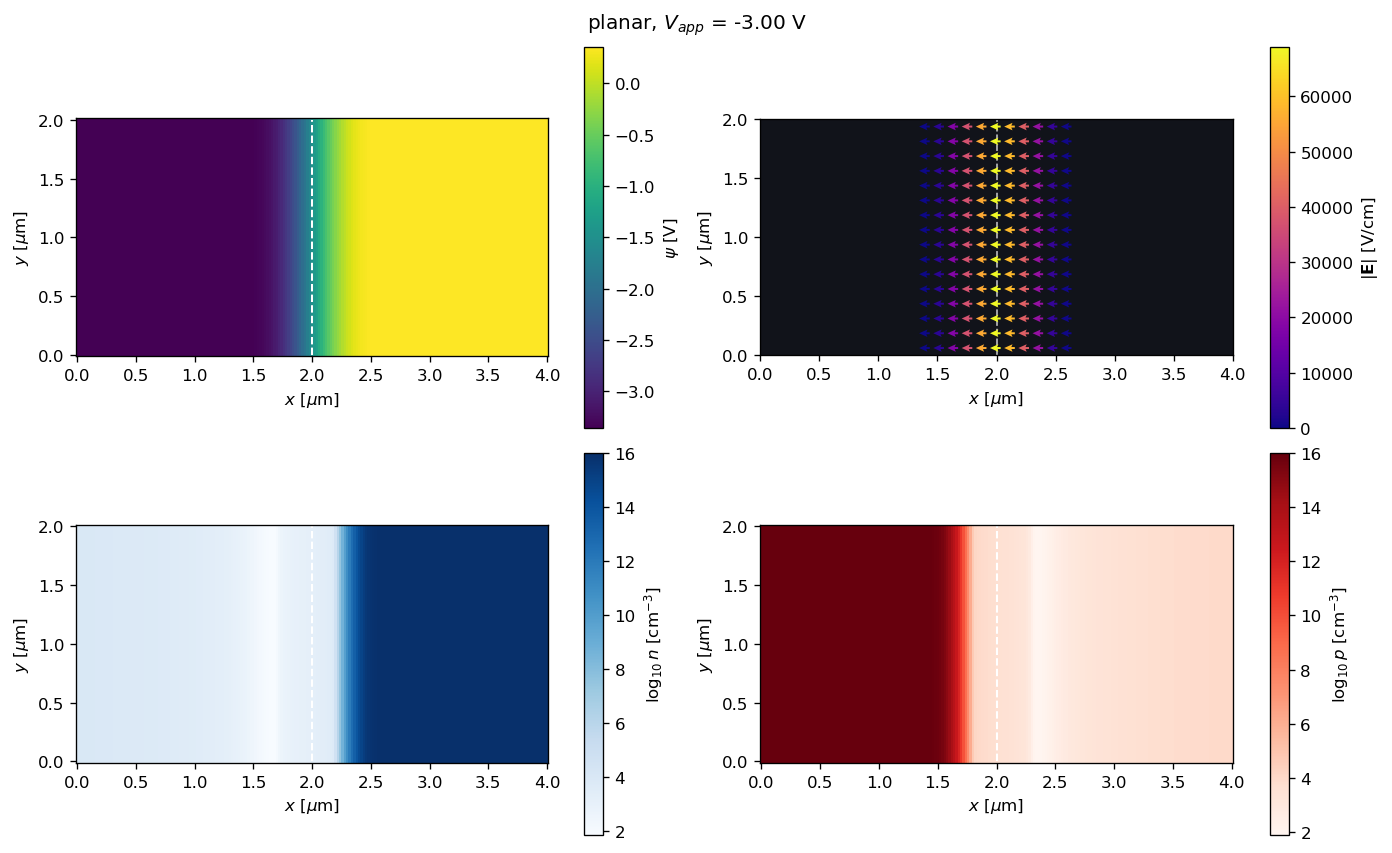

In [6]:
V_fwd = np.round(np.arange(0.05, 0.651, 0.05), 3)
V_rev = np.round(np.arange(-0.2, -3.001, -0.2), 3)
W_max = abrupt_depletion_width(cfg, V_rev.min())
print(f"Domain check at {V_rev.min():+.2f} V: W_d = {W_max*1e4:.3f} um, Lx/W_d = {cfg.Lx/W_max:.2f}")
assert cfg.Lx >= 3.0 * W_max

t0 = time.time()
states_planar = run_voltage_sweep(dev_planar, np.concatenate([V_fwd, V_rev]), eq=eq_planar)
print(f"Planar sweep ({len(states_planar)} bias points) solved in {time.time() - t0:.1f} s\n")

Vs = np.array(list(states_planar.keys()))
Is = np.array([terminal_current(dev_planar, s) for s in states_planar.values()])
print(f"{'V [V]':>7} {'I [A/cm]':>13} {'cons.err':>11} {'iters':>6}")
for v, i, s in zip(Vs, Is, states_planar.values()):
    ce = current_conservation_error(dev_planar, s) if v != 0.0 else 0.0
    print(f"{v:7.2f} {i:13.4e} {ce:11.2e} {s.iterations:6d}")
    if v != 0.0:
        assert ce < 1e-3

print(f"\nFitted ideality factor (0.25-0.55 V): {ideality_factor(Vs, Is, cfg.VT):.3f}")
plot_iv(Vs, Is, cfg.VT)
plt.show()

for v in (0.0, 0.6, -3.0):
    plot_dashboard(dev_planar, states_planar[v])
    plt.show()

## 7. Curvature / Electric-Field Crowding Study

We fix the wavelength $\lambda = L_y$ and use a cosine interface $f(y) = x_0 + A \cos(2\pi y / \lambda)$ (so $f'(0) = f'(L_y) = 0$ is mirror-compatible with the zero-flux top/bottom walls), keeping the doping width $w = 0.11\,\mu\text{m}$ constant across all amplitudes $A \in \{0.0, 0.1, 0.25, 0.4\}\,\mu\text{m}$ at $V_{\text{app}} = -2.0\text{ V}$.

We compute $\kappa_{\max} = A(2\pi/\lambda)^2 = 1/R_{c,\min}$, plot $|\mathbf{E}|_{\max}$ against $\kappa_{\max}$, and verify where the field maximum occurs relative to the high-curvature extrema ($y = 0, L_y/2, L_y$).

A=0.00 um | kappa_max= 0.000 1/um (Rc=   inf um) | |E|max=5.4154e+04 V/cm at (x=1.990, y=0.088) um | I=-7.321e-12 A/cm (cons=3.13e-13)
A=0.10 um | kappa_max= 0.987 1/um (Rc= 1.013 um) | |E|max=5.4300e+04 V/cm at (x=1.990, y=0.538) um | I=-7.411e-12 A/cm (cons=2.40e-14)
A=0.25 um | kappa_max= 2.467 1/um (Rc= 0.405 um) | |E|max=5.4745e+04 V/cm at (x=1.990, y=1.488) um | I=-7.871e-12 A/cm (cons=1.38e-14)
A=0.40 um | kappa_max= 3.948 1/um (Rc= 0.253 um) | |E|max=5.5492e+04 V/cm at (x=1.990, y=1.488) um | I=-8.661e-12 A/cm (cons=2.95e-14)


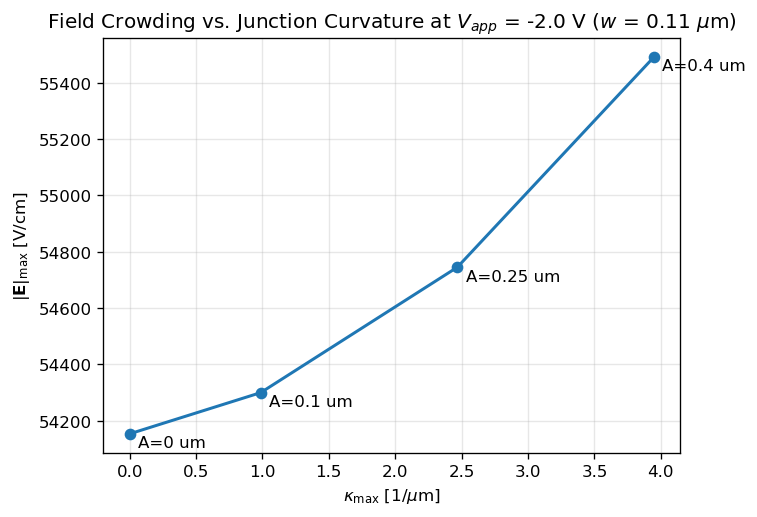

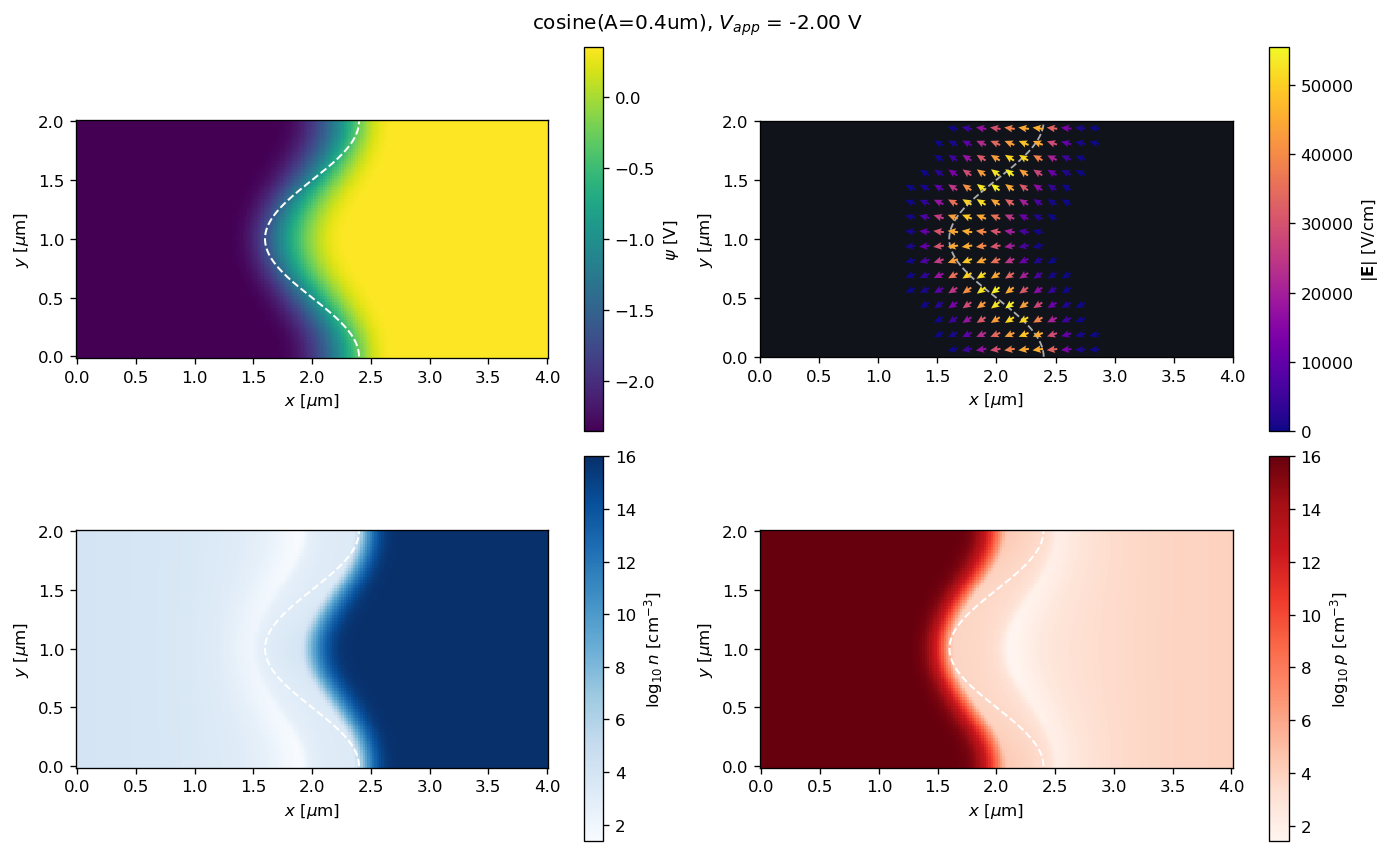

In [7]:
V_curv = -2.0
amplitudes = (0.0, 0.1, 0.25, 0.4)
w_curv = 0.11 * UM
lam = cfg.Ly
k_wave = 2.0 * np.pi / lam

curv_rows = []
curv_states = {}
for A in amplitudes:
    dev_c = Device(cfg, cosine(cfg.Lx / 2, A * UM, cfg.Ly), w=w_curv)
    eq_c = solve_equilibrium(dev_c)
    st_c = ramp(dev_c, solve_bias(dev_c, 0.0, eq_c), V_curv, SolverConfig().dV_reverse)
    xc, yc, Ex, Ey, Emag = electric_field(dev_c, st_c)
    j_max, i_max = np.unravel_index(np.argmax(Emag), Emag.shape)
    kappa_max = A * UM * k_wave**2
    I_c = terminal_current(dev_c, st_c)
    cons_c = current_conservation_error(dev_c, st_c)
    curv_rows.append((A, kappa_max, Emag.max(), xc[i_max], yc[j_max], I_c, cons_c))
    curv_states[A] = (dev_c, st_c)
    rc_str = f"{1/kappa_max*1e4:6.3f}" if kappa_max > 0 else "   inf"
    print(f"A={A:4.2f} um | kappa_max={kappa_max*1e-4:6.3f} 1/um (Rc={rc_str} um) | "
          f"|E|max={Emag.max():.4e} V/cm at (x={xc[i_max]*1e4:.3f}, y={yc[j_max]*1e4:.3f}) um | "
          f"I={I_c:.3e} A/cm (cons={cons_c:.2e})")

curv_arr = np.array(curv_rows)
fig, ax = plt.subplots(figsize=(6.2, 4.2), constrained_layout=True)
ax.plot(curv_arr[:, 1] * 1e-4, curv_arr[:, 2], "o-", lw=1.8)
for A, kap, Em in curv_arr[:, :3]:
    ax.annotate(f"A={A:g} um", (kap * 1e-4, Em), textcoords="offset points", xytext=(5, -8))
ax.set_xlabel(r"$\kappa_{\max}$ [1/$\mu$m]")
ax.set_ylabel(r"$|\mathbf{E}|_{\max}$ [V/cm]")
ax.set_title(rf"Field Crowding vs. Junction Curvature at $V_{{app}}$ = {V_curv:+.1f} V ($w$ = {w_curv*1e4:g} $\mu$m)")
ax.grid(True, alpha=0.3)
plt.show()

# Show 2x2 dashboard for the highest-curvature junction (A = 0.4 um)
dev_hi, st_hi = curv_states[0.4]
plot_dashboard(dev_hi, st_hi)
plt.show()